# ML HW1 - Question 3
**Soroush Nasiri | 810803098**

## a) Gaussian Naive Bayes
$$\pi_k=\frac{n_k}{n_{\mathrm{train}}}\qquad
\mu_{kj}=\frac1{n_k}\sum_{i:y_i=k}x_{ij}\qquad
\sigma^2_{kj}=\frac1{n_k}\sum_{i:y_i=k}(x_{ij}-\mu_{kj})^2$$
Treat variances below $10^{-12}$ as zero when counting them.

In [7]:
import numpy as np

raw = np.loadtxt('ecoli.csv', delimiter=',', dtype=str)
classes = np.array(['cp', 'im', 'pp', 'imU', 'om'])
X, y = raw[:, :7].astype(float), raw[:, -1]
keep = np.isin(y, classes)
X, y = X[keep], y[keep]

rng = np.random.default_rng(0)
train_idx, test_idx = [], []
for label in classes:
    indices = rng.permutation(np.flatnonzero(y == label))
    n_train = round(0.7 * len(indices))
    train_idx.extend(indices[:n_train])
    test_idx.extend(indices[n_train:])

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
priors = np.array([(y_train == label).mean() for label in classes])
means = np.array([X_train[y_train == label].mean(axis=0) for label in classes])
variances = np.array([X_train[y_train == label].var(axis=0) for label in classes])

print(f'Training: {len(y_train)}, test: {len(y_test)}')
print(f'Zero variances: {(variances < 1e-12).sum()}')
for label, count in zip(classes, (variances < 1e-12).sum(axis=1)):
    print(f'{label}: {count}')

Training: 228, test: 99
Zero variances: 8
cp: 2
im: 1
pp: 2
imU: 2
om: 1


Apply the variance floor $v_{kj}=\max(\sigma^2_{kj},\epsilon)$ and classify by the largest log score:
$$g_k(x)=\log\pi_k-\frac12\sum_j\left[\log(2\pi v_{kj})+\frac{(x_j-\mu_{kj})^2}{v_{kj}}\right]$$
Compute posteriors using log-sum-exp:
$$\log Z=m+\log\sum_k e^{g_k-m}\qquad m=\max_k g_k\qquad
P(k\mid x)=e^{g_k-\log Z}$$

In [8]:
def gaussian_nb(X, floor=1e-4):
    var = np.maximum(variances, floor)
    scores = np.log(priors) - 0.5 * np.sum(
        np.log(2 * np.pi * var) + (X[:, None, :] - means) ** 2 / var, axis=2)
    maximum = scores.max(axis=1, keepdims=True)
    log_z = maximum + np.log(np.exp(scores - maximum).sum(axis=1, keepdims=True))
    return classes[scores.argmax(axis=1)], np.exp(scores - log_z)

for floor in [1e-6, 1e-4, 1e-2]:
    predictions, _ = gaussian_nb(X_test, floor)
    print(f'Floor {floor:.0e}: test accuracy {(predictions == y_test).mean():.4%}')

y_pred, posteriors = gaussian_nb(X_test)

Floor 1e-06: test accuracy 73.7374%
Floor 1e-04: test accuracy 81.8182%
Floor 1e-02: test accuracy 84.8485%


There are **8 zero variances** before flooring. A positive floor prevents division by zero and undefined log densities. It does not prevent feature dominance: a small variance still gives a large penalt.

## b) Confusion matrix and classification metrics
Use the default variance floor $10^{-4}$. Confusion matrix rows are predicted classes and columns are true classes, in the order cp, im, pp, imU, om.
$$TP_k=C_{kk}\quad FP_k=\sum_j C_{kj}-TP_k\quad FN_k=\sum_i C_{ik}-TP_k$$
$$P_k=\frac{TP_k}{TP_k+FP_k}\qquad R_k=\frac{TP_k}{TP_k+FN_k}\qquad F_{1,k}=\frac{2TP_k}{2TP_k+FP_k+FN_k}$$
$$F_{1,\mathrm{micro}}=\frac{2\sum_k TP_k}{2\sum_k TP_k+\sum_k FP_k+\sum_k FN_k}$$
$$F_{1,\mathrm{macro}}=\frac{1}{K}\sum_{k=1}^{K}F_{1,k}\qquad
F_{1,\mathrm{weighted}}=\sum_{k=1}^{K}\frac{n_k}{N}F_{1,k}$$

Macro-F1:    76.7793%
Micro-F1:    81.8182%
Weighted-F1: 82.0475%
Accuracy:    81.8182%


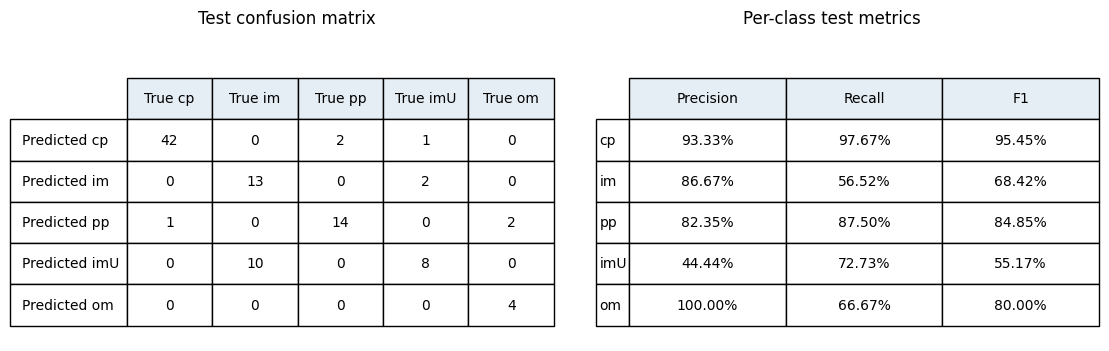

In [9]:
import matplotlib.pyplot as plt

confusion = np.array([[np.sum((y_pred == predicted) & (y_test == actual))
                       for actual in classes] for predicted in classes])
tp = np.diag(confusion)
fp = confusion.sum(axis=1) - tp
fn = confusion.sum(axis=0) - tp
support = confusion.sum(axis=0)
precision = np.divide(tp, tp + fp, out=np.zeros(len(classes)), where=(tp + fp) > 0)
recall = tp / (tp + fn)
f1 = 2 * tp / (2 * tp + fp + fn)
macro_f1 = f1.mean()
micro_f1 = 2 * tp.sum() / (2 * tp.sum() + fp.sum() + fn.sum())
weighted_f1 = np.average(f1, weights=support)

print(f'Macro-F1:    {macro_f1:.4%}')
print(f'Micro-F1:    {micro_f1:.4%}')
print(f'Weighted-F1: {weighted_f1:.4%}')
print(f'Accuracy:    {(y_pred == y_test).mean():.4%}')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
for ax in axes:
    ax.axis('off')
axes[0].set_title('Test confusion matrix')
axes[0].table(cellText=confusion, rowLabels=['Predicted ' + k for k in classes],
              colLabels=['True ' + k for k in classes], cellLoc='center',
              colColours=['#e6eef5'] * 5, bbox=[.2, .05, .8, .8])
metrics = [[f'{p:.2%}', f'{r:.2%}', f'{f:.2%}']
           for p, r, f in zip(precision, recall, f1)]
axes[1].set_title('Per-class test metrics')
axes[1].table(cellText=metrics, rowLabels=classes,
              colLabels=['Precision', 'Recall', 'F1'], cellLoc='center',
              colColours=['#e6eef5'] * 3, bbox=[.12, .05, .88, .8])
plt.show()

For $N$ single-label predictions, let $M$ be the number of correct predictions.
$$\sum_k TP_k=M\qquad \sum_k FP_k=\sum_k FN_k=N-M$$
Therefore,
$$F_{1,\mathrm{micro}}=\frac{2M}{2M+(N-M)+(N-M)}=\frac{M}{N}=\mathrm{Accuracy}$$

## c) Full-covariance Gaussian classifier
Estimate each full covariance from training data and add $\epsilon I$, with $\epsilon=10^{-4}$. Using the same priors, means and split, predict the class maximizing
$$g_k(x)=\log\pi_k-\frac12\log|\Sigma_k|-\frac12(x-\mu_k)^T\Sigma_k^{-1}(x-\mu_k)$$

In [10]:
epsilon = 1e-4
covariances = np.array([np.cov(X_train[y_train == label], rowvar=False, bias=True)
                        + epsilon * np.eye(X_train.shape[1]) for label in classes])
qda_scores = np.empty((len(X_test), len(classes)))
for k, covariance in enumerate(covariances):
    delta = X_test - means[k]
    distance = np.sum(delta * np.linalg.solve(covariance, delta.T).T, axis=1)
    qda_scores[:, k] = np.log(priors[k]) - 0.5 * (np.linalg.slogdet(covariance)[1] + distance)

qda_pred = classes[qda_scores.argmax(axis=1)]
print(f'Gaussian NB accuracy: {(y_pred == y_test).mean():.4%}')
print(f'QDA accuracy:         {(qda_pred == y_test).mean():.4%}')

Gaussian NB accuracy: 81.8182%
QDA accuracy:         80.8081%


QDA scores 80.8081%, slightly below Gaussian NB at 81.8182%.

For $d=7$ and $c=5$, the independent parameter counts are
$$\mathrm{GNB}: 74\qquad
\mathrm{QDA}: 179$$

For imL and imS, two samples give a covariance of rank at most $2-1=1<7$, so QDA is singular. Adding $\epsilon I$ makes it invertible, but two samples cannot reliably estimate a full covariance.